# Molecular Dynamics of 108 Lennard-Jones Particles (NVE)
**Follow-along tutorial** — we write our own MD engine from scratch.

**Plan**
1. The model: Lennard-Jones potential and forces
2. Units
3. Initial positions and velocities
4. Computing the forces
5. The integrator (Taylor series / velocity Verlet)
6. Run the NVE simulation and write an `.xyz` trajectory
7. Check energy conservation
8. What did the atoms do?
9. Visualize in VMD

System: 108 argon-like atoms in a 20 Å cubic box, constant energy (NVE), **no periodic boundary conditions**.

## 1. The model
Atoms interact through pairwise Lennard-Jones:

$$u(r) = 4\varepsilon\left[\left(\frac{\sigma}{r}\right)^{12} - \left(\frac{\sigma}{r}\right)^{6}\right]$$

The force on atom $i$ from atom $j$, with $\vec r_{ij} = \vec r_i - \vec r_j$:

$$\vec F_{ij} = \frac{24\varepsilon}{r_{ij}^2}\left[2\left(\frac{\sigma}{r_{ij}}\right)^{12} - \left(\frac{\sigma}{r_{ij}}\right)^{6}\right]\vec r_{ij}$$

Total force: $\vec F_i = \sum_{j\neq i}\vec F_{ij}$. Total potential energy: $U = \sum_{i<j}u(r_{ij})$.

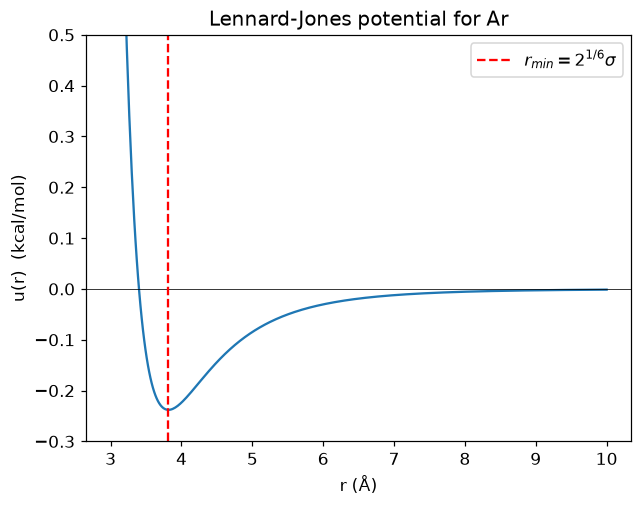

In [20]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "font.size": 11})

eps, sigma = 0.238, 3.4          # kcal/mol, Angstrom (argon)
r = np.linspace(3.0, 10, 400)
u = 4*eps*((sigma/r)**12 - (sigma/r)**6)

plt.plot(r, u)
plt.axhline(0, color="k", lw=.5)
plt.axvline(2**(1/6)*sigma, color="r", ls="--", label=r"$r_{min}=2^{1/6}\sigma$")
plt.ylim(-0.3, 0.5); plt.xlabel("r (Å)"); plt.ylabel("u(r)  (kcal/mol)")
plt.title("Lennard-Jones potential for Ar"); plt.legend(); plt.show()

## 2. Units
We use units where the numbers are convenient for atoms:

| Quantity | Unit |
|---|---|
| length | Å |
| mass | amu |
| energy | kcal/mol |
| time | ps |

Newton's law $a = F/m$ then needs a conversion factor:

$$1\ \frac{\text{kcal/mol}}{\text{Å}\cdot\text{amu}} = 418.4\ \text{Å/ps}^2$$

In [21]:
# ---- parameters ----
N      = 108
L      = 20.0          # box length (Å) - atoms are placed randomly inside this box
MIN_DIST = 3.4         # closest allowed distance between two atoms at the start (Å)
MASS   = 39.948        # amu
KB     = 0.0019872041  # kcal/mol/K
ACC    = 418.4         # (kcal/mol/Å)/amu  ->  Å/ps^2
T0     = 100.0         # initial temperature (K)
DT     = 0.002         # time step: 2 fs
NSTEPS = 5000          # 10 ps total
NOUT   = 10            # write a frame every 10 steps
rng    = np.random.default_rng(42)

## 3. Initial conditions

**Positions:** we place the 108 atoms at **random positions** inside the 20 Å box. There is one catch: if two atoms happen to land almost on top of each other, the $r^{-12}$ repulsion gives an enormous force and the simulation explodes. So we add one rule: pick a random spot, and **only keep it if it is at least `MIN_DIST` = 3.4 Å (about one $\sigma$) away from every atom placed so far**. Otherwise throw it away and pick a new spot.

**Velocities:** drawn from a Maxwell–Boltzmann distribution at $T_0$: each Cartesian component (vx, vy, vz) is a random Gaussian number with standard deviation $\sigma_v=\sqrt{k_BT/m}$. We then remove the centre-of-mass drift (so the whole cluster doesn't fly away) and rescale so the temperature is exactly $T_0$.

In [22]:
def init_positions():
    positions = []                     # atoms placed so far

    while len(positions) < N:
        # 1. pick a random point inside the box
        new = rng.uniform(0.0, L, 3)   # random x, y, z between 0 and L

        # 2. check its distance to every atom already placed
        too_close = False
        for old in positions:
            distance = np.sqrt(((new - old)**2).sum())
            if distance < MIN_DIST:
                too_close = True
                break

        # 3. keep the point only if it is not too close to any other atom
        if not too_close:
            positions.append(new)

    return np.array(positions)         # table with 108 rows (atoms) and 3 columns (x, y, z)


def kinetic(v):
    # Kinetic energy = sum of (1/2) m v^2 over all atoms.
    # (v**2).sum() adds up vx^2 + vy^2 + vz^2 for every atom.
    # Dividing by ACC converts the units to kcal/mol.
    return 0.5 * MASS * (v**2).sum() / ACC


def init_velocities():
    # Spread (standard deviation) of each velocity component, in Å/ps
    sd = np.sqrt(KB * T0 / MASS * ACC)

    # Random Gaussian velocities: 108 atoms x 3 components
    v = rng.normal(0.0, sd, (N, 3))

    # Remove the average velocity so the total momentum is zero
    v = v - v.mean(axis=0)

    # The random numbers give a temperature only close to T0, so rescale
    T = 2 * kinetic(v) / (3 * (N - 1) * KB)   # temperature we actually got
    scale = np.sqrt(T0 / T)
    return v * scale


r0 = init_positions()
v0 = init_velocities()
print("atoms:", len(r0))
print("positions range (Å):", r0.min(axis=0).round(2), "to", r0.max(axis=0).round(2))

atoms: 108
positions range (Å): [0.08 0.25 0.03] to [19.98 19.98 19.99]


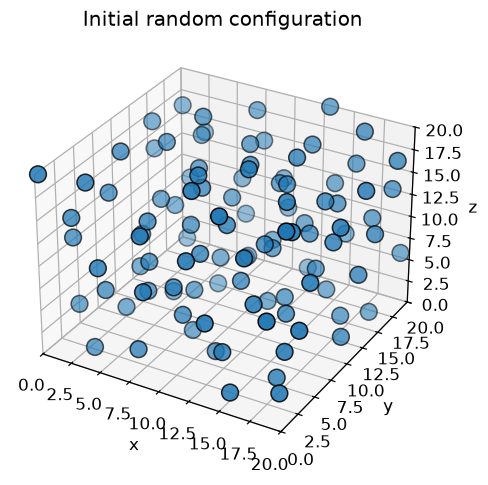

In [23]:
x, y, z = r0.T      # split the table of positions into x, y and z values
fig = plt.figure(figsize=(5.5,5))
ax = fig.add_subplot(projection="3d")
ax.scatter(x, y, z, s=120, c="tab:blue", edgecolor="k")
ax.set_xlim(0,L); ax.set_ylim(0,L); ax.set_zlim(0,L)
ax.set_xlabel("x"); ax.set_ylabel("y"); ax.set_zlabel("z"); ax.set_title("Initial random configuration")
plt.show()

## 4. Forces
For each atom `i`:
1. Compute the vector from every atom `j` to atom `i` (`d`) and the squared distance to each of them (`r2`).
2. Set the distance of atom `i` to itself to infinity, so an atom feels no force from itself (its LJ terms become zero).
3. Use the force formula from Section 1 to get a force factor `fmag` for every `j`.
4. The force on atom `i` is the sum over all `j` of `fmag[j] × d[j]`. `np.dot(fmag, d)` does exactly this sum.

For the energy, every pair is counted twice (once from each atom), so we multiply by ½.

In [24]:
def forces(pos):
    F = np.zeros((N, 3))     # force on every atom (x, y, z)
    U = 0.0                  # total potential energy

    for i in range(N):
        d = pos[i] - pos                    # vectors from every atom j to atom i
        r2 = (d * d).sum(axis=1)            # squared distance to every atom j
        r2[i] = np.inf                      # no force from itself

        s6 = (sigma**2 / r2)**3             # (sigma/r)^6
        fmag = 24*eps*(2*s6**2 - s6) / r2   # force factor from Section 1

        F[i] = np.dot(fmag, d)              # add up the force from all other atoms
        U += 2*eps*(s6**2 - s6).sum()       # each pair is counted twice, hence 2*eps instead of 4*eps

    return F, U

F0, U0 = forces(r0)
print("U0 =", round(U0,3), "kcal/mol")
print("net force (should be ~0 by Newton's 3rd law):", F0.sum(axis=0).round(10))

U0 = -53.753 kcal/mol
net force (should be ~0 by Newton's 3rd law): [-0.  0. -0.]


## 5. The integrator: Taylor series
Expand the position about time $t$:

$$\vec r(t+\Delta t)=\vec r(t)+\vec v(t)\,\Delta t+\tfrac12\vec a(t)\,\Delta t^2+O(\Delta t^3)$$

and the velocity, approximating the acceleration change over the step by its average:

$$\vec v(t+\Delta t)=\vec v(t)+\tfrac12\big[\vec a(t)+\vec a(t+\Delta t)\big]\Delta t$$

This is the **velocity Verlet** algorithm. One MD step:

1. update positions with $\vec r(t),\vec v(t),\vec a(t)$
2. compute new forces → $\vec a(t+\Delta t)$
3. update velocities with the average of old and new $\vec a$
4. keep $\vec a(t+\Delta t)$ for the next step

Only **one** force evaluation per step. Frames are written in `.xyz` format:
```
108
comment line
Ar x y z
... (108 lines)
```

In [25]:
def write_xyz(f, pos, step):
    f.write(f"{N}\nstep {step}\n")
    for x, y, z in pos:
        f.write(f"Ar {x:.5f} {y:.5f} {z:.5f}\n")

def run_md():
    pos = r0.copy()                  # start from the initial positions
    vel = v0.copy()                  # and the initial velocities
    F, U = forces(pos)
    acc = F / MASS * ACC             # acceleration = force / mass

    times, K_list, U_list, frames = [], [], [], []
    f = open("traj.xyz", "w")

    for step in range(NSTEPS + 1):
        K = kinetic(vel)

        # save data every NOUT steps
        if step % NOUT == 0:
            times.append(step * DT)
            K_list.append(K)
            U_list.append(U)
            frames.append(pos.copy())
            write_xyz(f, pos, step)

        # velocity Verlet: one MD step
        pos = pos + vel*DT + 0.5*acc*DT**2       # 1. new positions
        F, U = forces(pos)                       # 2. new forces
        new_acc = F / MASS * ACC
        vel = vel + 0.5*(acc + new_acc)*DT       # 3. new velocities
        acc = new_acc                            # 4. keep for the next step

    f.close()
    return np.array(times), np.array(K_list), np.array(U_list), frames

## 6. Run the simulation (10 ps, Δt = 2 fs) and write `traj.xyz`

In [26]:
import time
t0 = time.time()
t, K, U, frames = run_md()
print(f"done in {time.time()-t0:.1f} s, {len(frames)} frames written")

E = K + U                  # total energy
T = 2*K/(3*N*KB)           # temperature

done in 4.0 s, 501 frames written


In [27]:
!head -5 traj.xyz
!grep -c Ar traj.xyz

108
step 0
Ar 15.47912 8.77757 17.17196
Ar 13.94736 1.88355 19.51245
Ar 15.22279 15.72129 2.56227
54108


## 7. Is energy conserved?
In NVE, $E=K+U$ must stay constant. Kinetic and potential energy exchange, but their sum should not drift. This is the key test that our integrator and forces are correct.

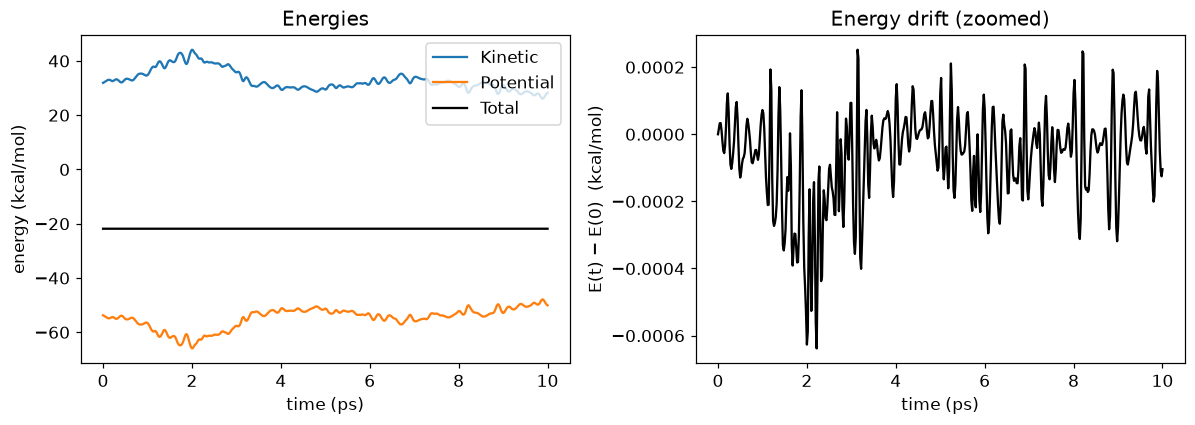

max |E-E0| = 6.38e-04 kcal/mol  (2.9e-05 relative)


In [28]:
fig, ax = plt.subplots(1,2, figsize=(11,4))
ax[0].plot(t, K, label="Kinetic"); ax[0].plot(t, U, label="Potential"); ax[0].plot(t, E, "k", label="Total")
ax[0].set_xlabel("time (ps)"); ax[0].set_ylabel("energy (kcal/mol)"); ax[0].legend(); ax[0].set_title("Energies")
ax[1].plot(t, E - E[0], "k"); ax[1].set_xlabel("time (ps)"); ax[1].set_ylabel("E(t) − E(0)  (kcal/mol)")
ax[1].set_title("Energy drift (zoomed)")
plt.tight_layout(); plt.show()
print(f"max |E-E0| = {abs(E-E[0]).max():.2e} kcal/mol  ({abs(E-E[0]).max()/abs(E[0]):.1e} relative)")

Total energy is flat to ~$10^{-3}$ kcal/mol (the small wiggles are the $O(\Delta t^2)$ integration error), while K and U individually change a lot.

**Temperature** from equipartition, $\langle K\rangle=\tfrac32Nk_BT$. The atoms start at random spots and attract each other, so potential energy drops at first and the atoms speed up (the temperature rises above 100 K). Later the cluster spreads out again and the temperature falls. Kinetic and potential energy keep trading places, but their sum stays constant.

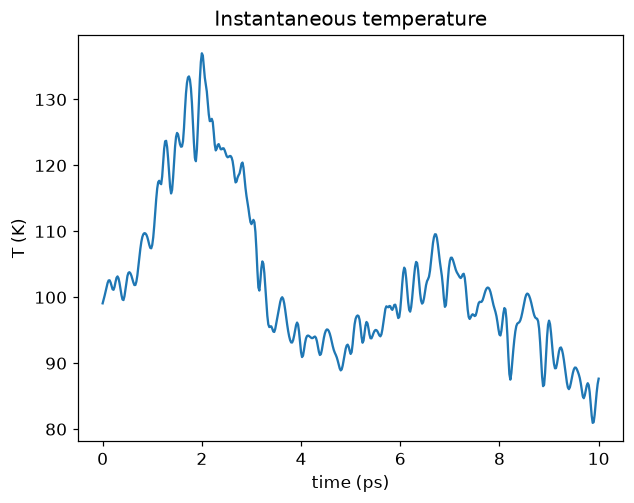

In [29]:
plt.plot(t, T); plt.xlabel("time (ps)"); plt.ylabel("T (K)"); plt.title("Instantaneous temperature"); plt.show()

## 8. What did the atoms do?
Snapshots of the first, middle and last frames. The atoms start scattered randomly in the box. Because they attract each other, they first pull together into a loose cluster. Without periodic boundaries nothing confines them, so the cluster then gradually expands and some atoms evaporate.

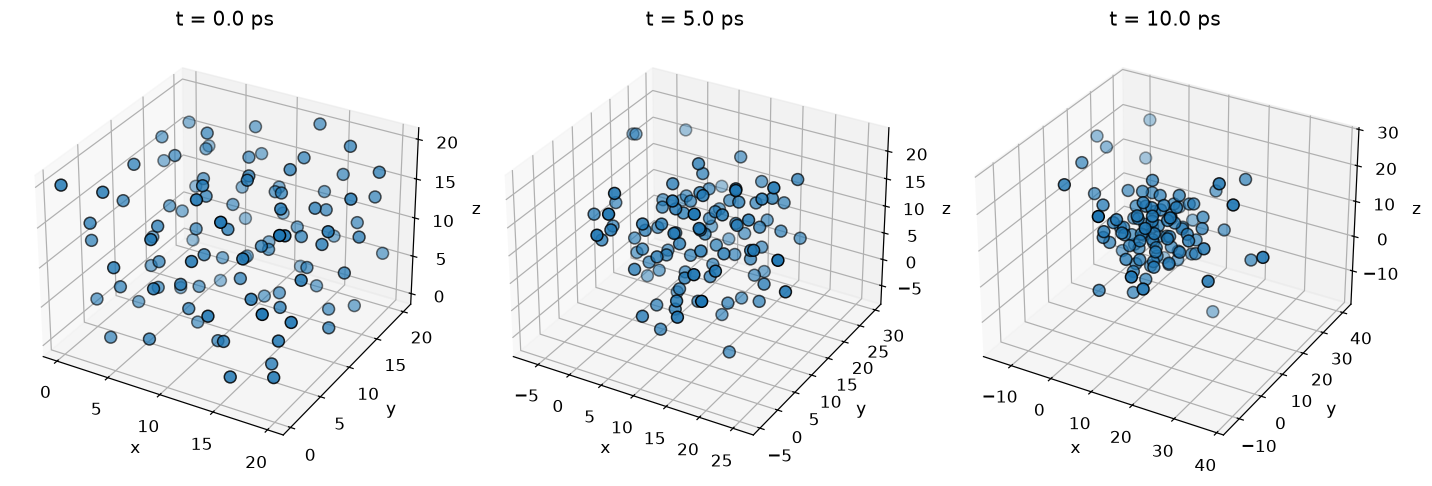

In [30]:
fig = plt.figure(figsize=(13,4.5))
last = len(frames) - 1
middle = len(frames) // 2

for k, idx in enumerate([0, middle, last]):
    x, y, z = frames[idx].T      # x, y, z values of all atoms in this frame
    ax = fig.add_subplot(1,3,k+1, projection="3d")
    ax.scatter(x, y, z, s=60, edgecolor="k")
    ax.set_title(f"t = {t[idx]:.1f} ps")
    ax.set_xlabel("x"); ax.set_ylabel("y"); ax.set_zlabel("z")
plt.tight_layout(); plt.show()

## 9. Visualize in VMD
From a terminal in this folder:
```
vmd traj.xyz
```
Then in VMD:
1. *Graphics → Representations → Drawing Method → **VDW*** (set sphere scale ≈ 0.6–0.8)
2. Press the play button at the bottom of the main window to animate
3. *Display → Orthographic*, and *Graphics → Representations → Selected Atoms* lets you colour by index to track individual atoms
4. Optional: *Extensions → Visualization → Movie Maker* to export a movie

Things to look for: atoms starting scattered, drifting together into a loose cluster, and then some atoms leaving it.

## Summary
- LJ pair potential → forces → Newton's equations $m\ddot{\vec r}=\vec F$
- Taylor expansion (velocity Verlet) integrates them stepwise with one force call per step
- We wrote the whole engine ourselves, wrote an `.xyz` trajectory, and viewed it in VMD
- **Energy conservation** is the check of correctness
- Not included (next topics): periodic boundary conditions, cutoffs/neighbour lists, thermostats (NVT), RDF and other analysis